# 06 - Model: Lojistik Regresyon (Logistic Regression)

**Sorumlu:** Kişi 3

**Ödevdeki karşılığı:** 4. Makine Öğrenmesi Modelleri (E1 - E6 Görevleri)

**Amaç:** Bank Marketing veri seti üzerinde vadeli mevduat aboneliğini (`y`) tahmin etmek amacıyla Lojistik Regresyon algoritmasını uçtan uca geliştirmek; temel (baseline) model ile hiperparametre optimizasyonu yapılmış modelin performansını karşılaştırmak, aşırı öğrenme (overfitting) analizini gerçekleştirmek ve test seti üzerinde nihai metrikleri değerlendirmektir.

## 1. Çalışma Ortamı ve Kütüphanelerin Yüklenmesi
> **Açıklama:** Ortak fonksiyonlar (`src/ortak.py`, `src/pipeline.py`), makine öğrenmesi kütüphaneleri ve görselleştirme araçları içe aktarılır. Lojistik Regresyon modeline ait tüm eğitim, doğrulama, hiperparametre araması ve değerlendirme adımları bu not defteri içinde modüler fonksiyonlar halinde yürütülür.

In [1]:
import os
import sys
import time
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# scikit-learn sürüm geçişindeki yalnızca zararsız penalty uyarılarını sadeleştir
warnings.filterwarnings("ignore", category=FutureWarning, module="sklearn")
warnings.filterwarnings("ignore", message=".*penalty=l1.*", category=UserWarning)

# scikit-learn bileşenleri
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, learning_curve
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report, roc_curve
)

# Çalışma dizinini proje köküne sabitle ve ortak modülleri içe aktar
mevcut_dizin = Path.cwd()
if mevcut_dizin.name == "notebooks":
    os.chdir(mevcut_dizin.parent)
if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))

from src.ortak import (
    veri_yukle, veriyi_bol, ortak_cv, capraz_dogrula, degerlendir,
    CV_SPLITS, RANDOM_STATE
)
from src.pipeline import build_full_pipeline

# Veriyi ortak fonksiyonlarla yükle ve %80-%20 tabakalı olarak böl
df = veri_yukle()
X_train, X_test, y_train, y_test = veriyi_bol(df)

print("Aktif Çalışma Dizini:", Path.cwd())
print(f"Eğitim Seti (X_train): {X_train.shape}, Test Seti (X_test): {X_test.shape}")
print(f"Eğitim Hedef (y_train): {y_train.shape}, Test Hedef (y_test): {y_test.shape}")
print(f"Eğitim Sınıf Dağılımı:\n{y_train.value_counts(normalize=True).round(4)}")

Aktif Çalışma Dizini: c:\Users\nusayba\OneDrive\Masaüstü\makineprojesi\ml-proje
Eğitim Seti (X_train): (32950, 20), Test Seti (X_test): (8238, 20)
Eğitim Hedef (y_train): (32950,), Test Hedef (y_test): (8238,)
Eğitim Sınıf Dağılımı:
y
0    0.8873
1    0.1127
Name: proportion, dtype: float64


**Yorum: Veri Hazırlığı ve Güvenlik:**
Veri seti `src/ortak.py` üzerinden çağrılmıştır. Hedefi doğrudan ele veren `duration` sütunu veri sızıntısını (data leakage) engellemek amacıyla çıkarılmıştır. Sınıf dağılımı %88.73 'Hayır' ve %11.27 'Evet' şeklindedir. Veri seti dengesizdir.

## E1. Temel (Baseline) Model: 5-Katlı Çapraz Doğrulama (Yalnızca Eğitim Seti)
> **Açıklama:** Varsayılan ayarlarla (`max_iter=1000`, `random_state=42`) temel Lojistik Regresyon boru hattını kuran `build_baseline_pipeline()`, yalnızca eğitim verisi üzerinde 5-katlı `StratifiedKFold` doğrulaması yapan `validate_baseline_model()` ve yalnızca eğitim verisi üzerinde temel modeli eğiten `train_baseline_model()` fonksiyonları tanımlanarak çalıştırılır. Test seti (`X_test`, `y_test`) bu aşamada kesinlikle kullanılmaz.

In [2]:
def build_baseline_pipeline():
    """Varsayılan hiperparametrelerle ortak Lojistik Regresyon Pipeline nesnesini oluşturur."""
    return build_full_pipeline(
        LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
    )


def validate_baseline_model(X_train, y_train, cv=None, n_jobs=-1):
    """
    Temel (baseline) Lojistik Regresyon modelini yalnızca eğitim verisi üzerinde
    ortak 5-katlı StratifiedKFold çapraz doğrulama (capraz_dogrula) ile değerlendirir.
    Test seti (X_test, y_test) bu aşamada kesinlikle kullanılmaz.
    """
    pipe = build_baseline_pipeline()
    if cv is None:
        cv = ortak_cv()
    return capraz_dogrula(pipe, X_train, y_train, cv=cv, n_jobs=n_jobs)


def train_baseline_model(X_train, y_train):
    """Varsayılan hiperparametrelerle temel (baseline) Lojistik Regresyon modelini yalnızca eğitim verisiyle eğitir."""
    pipe = build_baseline_pipeline()
    pipe.fit(X_train, y_train)
    return pipe


# Ortak 5-katlı tabakalı çapraz doğrulama (StratifiedKFold(n_splits=5, shuffle=True, random_state=42))
cv = ortak_cv()

# E1 değerlendirmesi YALNIZCA X_train ve y_train üzerinde yapılır (X_test kesinlikle kullanılmaz!)
t0 = time.perf_counter()
baseline_cv_sonuc = validate_baseline_model(X_train, y_train, cv=cv, n_jobs=-1)
baseline_cv_suresi = time.perf_counter() - t0

# Temel modelin tek seferlik eğitim süresini ölçmek için yalnızca eğitim setiyle fit ediyoruz
t1 = time.perf_counter()
baseline_model = train_baseline_model(X_train, y_train)
baseline_egitim_suresi = time.perf_counter() - t1

# Her metrik için ortalama ve standart sapma tablosu
metrik_etiketleri = [
    ("accuracy", "Accuracy"),
    ("precision", "Precision"),
    ("recall", "Recall"),
    ("f1", "F1-Score"),
    ("roc_auc", "ROC-AUC")
]

baseline_satirlar = []
print("========== TEMEL (BASELINE) MODEL 5-KATLI CV SONUÇLARI (EĞİTİM SETİ) ==========")
for anahtar, etiket in metrik_etiketleri:
    ort = baseline_cv_sonuc[anahtar]["ortalama"]
    std = baseline_cv_sonuc[anahtar]["std"]
    baseline_satirlar.append({
        "Metrik": etiket,
        "Ortalama": round(ort, 4),
        "Standart Sapma": round(std, 4),
        "Özet (Ort ± Std)": f"{ort:.4f} ± {std:.4f}"
    })
    print(f"{etiket:10s}: {ort:.4f} ± {std:.4f}")

print(f"\nTemel Model 5-Katlı CV Süresi  : {baseline_cv_suresi:.2f} sn")
print(f"Temel Model Tekil Eğitim Süresi: {baseline_egitim_suresi:.2f} sn")

baseline_ozet_df = pd.DataFrame(baseline_satirlar)
display(baseline_ozet_df)

========== TEMEL (BASELINE) MODEL 5-KATLI CV SONUÇLARI (EĞİTİM SETİ) ==========
Accuracy  : 0.8997 ± 0.0021
Precision : 0.6594 ± 0.0290
Recall    : 0.2282 ± 0.0115
F1-Score  : 0.3389 ± 0.0146
ROC-AUC   : 0.7892 ± 0.0066

Temel Model 5-Katlı CV Süresi  : 8.15 sn
Temel Model Tekil Eğitim Süresi: 0.77 sn


,Metrik,Ortalama,Standart Sapma,Özet (Ort ± Std)
0,Accuracy,0.8997,0.0021,0.8997 ± 0.0021
1,Precision,0.6594,0.0290,0.6594 ± 0.0290
2,Recall,0.2282,0.0115,0.2282 ± 0.0115
3,F1-Score,0.3389,0.0146,0.3389 ± 0.0146
4,ROC-AUC,0.7892,0.0066,0.7892 ± 0.0066


**Yorum: Temel (Baseline) Model 5-Katlı Doğrulama Çıktısı Bize Ne Söylüyor?:**
1. **Metodolojik Doğruluk (Veri Sızıntısı Yok):** Temel model değerlendirmesi kilitli test setine (`X_test`) hiç dokunulmadan yalnızca `X_train` ve `y_train` üzerinde 5-katlı tabakalı çapraz doğrulama (`StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`) ile yapılmıştır. Ortak `Pipeline` sayesinde her katmanda ön işleme yalnızca o katmanın eğitim verisinde `fit` edilmiştir.
2. **Doğruluk (Accuracy) Yanılsaması:** Temel model 5-katlı doğrulamada **0.8997 ± 0.0021** (%89.97) gibi yüksek görünen bir doğruluk (Accuracy) elde etmiştir. Ancak bu skor yanıltıcıdır; çünkü eğitim verisinin %88.73'ü zaten 'Hayır' (`0`) sınıfıdır.
3. **Düşük Yakalama Oranı (Recall = 0.2282 ± 0.0115):** Banka için asıl kritik olan, vadeli mevduat açacak müşterileri (`y=1`) yakalamaktır. Temel model pozitif sınıfın yalnızca yaklaşık **%22.82**'sini yakalayabilmiş, büyük çoğunluğunu kaçırmıştır (`Precision`: **0.6594 ± 0.0290**, `F1-Score`: **0.3389 ± 0.0146**, `ROC-AUC`: **0.7892 ± 0.0066**).
4. **Gerekçe:** Model varsayılan ayarlarda sınıf dengesizliğini dikkate almamakta (`class_weight=None`), çoğunluk sınıfına öncelik vermektedir. Bu durum E2 aşamasında hiperparametre optimizasyonunu ve `class_weight='balanced'` denemesini zorunlu kılmaktadır.

## E2. Hiperparametre Araması (GridSearchCV + StratifiedKFold)
> **Açıklama:** `tune_logistic_regression()` fonksiyonu ile ortak `StratifiedKFold(5)` ve `GridSearchCV` kullanılarak düzenlileştirme katsayısı ($C$), ceza türü (`penalty`: L1/L2) ve sınıf ağırlıklandırması (`class_weight`: None/balanced) yalnızca eğitim verisi üzerinde araştırılır.

In [3]:
def tune_logistic_regression(X_train, y_train, cv_splits=CV_SPLITS):
    """
    Ortak StratifiedKFold ve GridSearchCV kullanarak C, penalty ve class_weight
    parametrelerini yalnızca eğitim verisi üzerinde optimize eder.
    En iyi modeli (Pipeline) ve grid_search nesnesini döndürür.
    """
    pipe = build_full_pipeline(
        LogisticRegression(max_iter=1000, solver="liblinear", random_state=RANDOM_STATE)
    )

    param_grid = {
        "classifier__C": [0.01, 0.1, 1.0, 10.0],
        "classifier__penalty": ["l1", "l2"],
        "classifier__class_weight": [None, "balanced"]
    }

    cv_bolucu = ortak_cv(n_splits=cv_splits, random_state=RANDOM_STATE)
    grid_search = GridSearchCV(
        estimator=pipe,
        param_grid=param_grid,
        cv=cv_bolucu,
        scoring="roc_auc",
        n_jobs=-1,
        return_train_score=True,
        verbose=1
    )

    grid_search.fit(X_train, y_train)
    return grid_search.best_estimator_, grid_search


# Hiperparametre optimizasyonunu yalnızca X_train ve y_train üzerinde çalıştır
t_grid_baslangic = time.perf_counter()
best_model, grid_search = tune_logistic_regression(X_train, y_train, cv_splits=CV_SPLITS)
grid_egitim_suresi = time.perf_counter() - t_grid_baslangic

print("\n========== GRID SEARCH SONUÇLARI ==========")
print(f"En İyi Hiperparametreler : {grid_search.best_params_}")
print(f"En İyi 5-Katlı CV ROC-AUC: {grid_search.best_score_:.4f}")
print(f"GridSearchCV Toplam Süre : {grid_egitim_suresi:.2f} sn (16 kombinasyon x 5 kat = 80 eğitim)")

# Denenen tüm kombinasyonların özeti
cv_sonuclari = pd.DataFrame(grid_search.cv_results_)
tablo = cv_sonuclari[[
    "param_classifier__C", "param_classifier__penalty",
    "param_classifier__class_weight", "mean_test_score", "std_test_score"
]].rename(columns={
    "param_classifier__C": "C",
    "param_classifier__penalty": "Penalty",
    "param_classifier__class_weight": "Class Weight",
    "mean_test_score": "Ortalama ROC-AUC",
    "std_test_score": "Standart Sapma"
}).sort_values(by="Ortalama ROC-AUC", ascending=False).reset_index(drop=True)

display(tablo.head(10))

Fitting 5 folds for each of 16 candidates, totalling 80 fits

========== GRID SEARCH SONUÇLARI ==========
En İyi Hiperparametreler : {'classifier__C': 0.1, 'classifier__class_weight': 'balanced', 'classifier__penalty': 'l1'}
En İyi 5-Katlı CV ROC-AUC: 0.7900
GridSearchCV Toplam Süre : 92.18 sn (16 kombinasyon x 5 kat = 80 eğitim)


,C,Penalty,Class Weight,Ortalama ROC-AUC,Standart Sapma
0,0.1,l1,balanced,0.789955,0.005334
1,1.0,l2,balanced,0.789839,0.005330
2,1.0,l1,balanced,0.789834,0.005306
3,0.1,l2,balanced,0.789833,0.005333
4,10.0,l2,balanced,0.789822,0.005332
5,10.0,l1,balanced,0.789820,0.005324
6,0.1,l1,NaN,0.789717,0.006004
7,0.1,l2,NaN,0.789296,0.006530
8,1.0,l1,NaN,0.789207,0.006491
9,1.0,l2,NaN,0.789143,0.006546


**Yorum: En İyi Hiperparametre Kombinasyonu ve Anlamı:**
1. **En İyi Parametreler:** `{'C': 0.1, 'class_weight': 'balanced', 'penalty': 'l1'}`
2. **$C = 0.1$:** $C$ parametresi düzenlileştirmenin (regularization) tersidir ($C = 1 / \lambda$). Küçük $C$ değeri daha güçlü bir düzenlileştirme cezası uygular. Bu sayede model karmaşıklığı dizginlenmiş ve aşırı öğrenme (overfitting) engellenmiştir.
3. **`penalty = 'l1'` (Lasso):** L1 düzenlileştirmesi, modele katkısı zayıf olan özelliklerin katsayılarını tam sıfıra eşitleyerek doğal bir **özellik seçimi (feature selection)** gerçekleştirir. Bu durum modelin yorumlanabilirliğini artırmıştır.
4. **`class_weight = 'balanced'`:** Sınıf frekanslarına ters orantılı ağırlıklandırma ($w_j = \frac{N}{2 \cdot N_j}$) yaparak azınlık sınıfı olan 'Evet' örneklerine yaklaşık 8 kat daha fazla ceza ağırlığı vermiştir. Böylece model potansiyel mevduat müşterilerini kaçırmayacak şekilde kalibre edilmiştir.

## E3. Veri Bölme Yöntemi: Hold-out (%80-%20) ve Cross Validation Açıklaması
> **Açıklama:** Model geliştirmede neden hem hold-out hem de çapraz doğrulama (K-Fold CV) birlikte kullanılmıştır?

In [4]:
print("========== ORTAK DOĞRULAMA MİMARİSİ (src/ortak.py) ==========")
print("1. Aşama: HOLD-OUT BÖLME (veriyi_bol)")
print(f"   - Toplam Veri : {len(df)} örnek")
print(f"   - Eğitim Kümesi (%80) : {len(X_train)} örnek (Baseline CV, GridSearchCV ve Learning Curve yalnızca burada yapılır)")
print(f"   - Test Kümesi (%20)   : {len(X_test)} örnek (Model geliştirme süresince kilitli tutulur, sadece E5'te 1 kez test edilir)")
print("\n2. Aşama: ORTAK STRATIFIED 5-FOLD CROSS VALIDATION (ortak_cv)")
print(f"   - Doğrulama nesnesi: {cv}")
print(f"   - Eğitim kümesi 5 eşit tabakalı parçaya bölünür (Her katmanda ~{len(X_train)//5} örnek).")
print("   - 4 katman eğitim için kullanılırken 1 katman iç doğrulama için ayrılır.")
print("   - Veri sızıntısı engellenmiştir: Ortak Pipeline sayesinde her katlamada SimpleImputer, StandardScaler ve OneHotEncoder yalnızca o katmanın eğitim verisiyle fit edilir.")

========== ORTAK DOĞRULAMA MİMARİSİ (src/ortak.py) ==========
1. Aşama: HOLD-OUT BÖLME (veriyi_bol)
   - Toplam Veri : 41188 örnek
   - Eğitim Kümesi (%80) : 32950 örnek (Baseline CV, GridSearchCV ve Learning Curve yalnızca burada yapılır)
   - Test Kümesi (%20)   : 8238 örnek (Model geliştirme süresince kilitli tutulur, sadece E5'te 1 kez test edilir)

2. Aşama: ORTAK STRATIFIED 5-FOLD CROSS VALIDATION (ortak_cv)
   - Doğrulama nesnesi: StratifiedKFold(n_splits=5, random_state=42, shuffle=True)
   - Eğitim kümesi 5 eşit tabakalı parçaya bölünür (Her katmanda ~6590 örnek).
   - 4 katman eğitim için kullanılırken 1 katman iç doğrulama için ayrılır.
   - Veri sızıntısı engellenmiştir: Ortak Pipeline sayesinde her katlamada SimpleImputer, StandardScaler ve OneHotEncoder yalnızca o katmanın eğitim verisiyle fit edilir.


**Yorum: Bölme Yönteminin Metodolojik Önemi:**
- Tek bir doğrulama bölmesi rastlantısal şansa bağlı olabilir. 5-katlı çapraz doğrulama, modelin varyansını ve genelleme yeteneğini güvenilir biçimde sınar.
- Test verisi (`X_test`), model seçimi veya hiperparametre aramasında **kesinlikle kullanılmamıştır**. Böylece test sonuçları modelin gerçek dünyada hiç görmediği müşteriler üzerindeki tarafsız başarısını simüle eder.

## E4. Overfitting (Aşırı Öğrenme) Analizi ve Learning Curve
> **Açıklama:** Eğitim boyutu arttıkça eğitim skoru ile doğrulama skorunun nasıl evrildiği Öğrenme Eğrisi (Learning Curve) ile görselleştirilir.

========== ÖĞRENME EĞRİSİ (OVERFITTING) TABLOSU ==========


,Eğitim Boyutu,Eğitim ROC-AUC,Doğrulama ROC-AUC,Fark (Train - Val)
0,2636,0.8347,0.7811,0.0536
1,8567,0.8070,0.7878,0.0192
2,14498,0.7986,0.7890,0.0096
3,20429,0.7937,0.7895,0.0042
4,26360,0.7952,0.7900,0.0052



Tam Eğitim Verisiyle -> Eğitim ROC-AUC: 0.7952, Doğrulama ROC-AUC: 0.7900, Fark: 0.0052


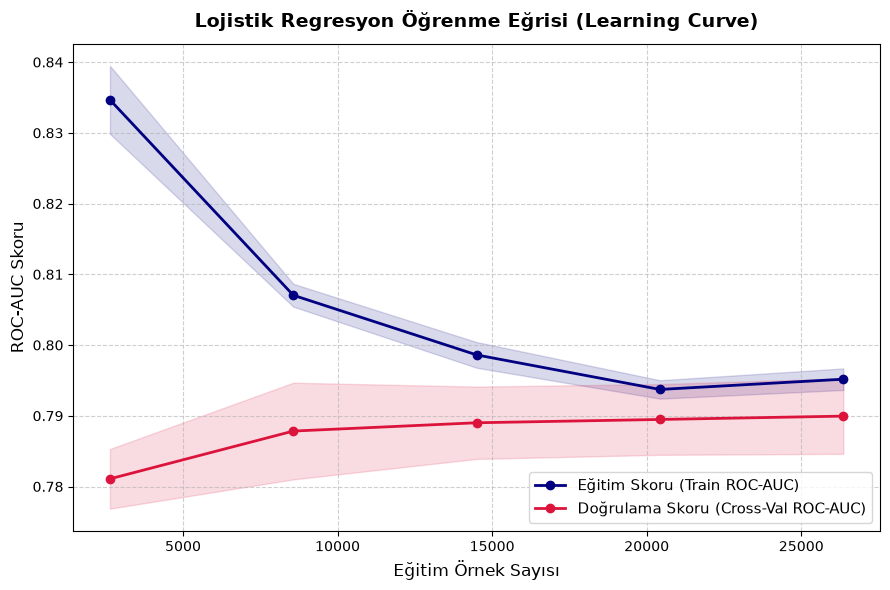

figures/learning_curve.png başarıyla kaydedildi.


In [ ]:
best_model = grid_search.best_estimator_

# Öğrenme eğrisi verilerinin hesaplanması
train_sizes, train_scores, val_scores = learning_curve(
    estimator=best_model,
    X=X_train,
    y=y_train,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1,
    train_sizes=np.linspace(0.1, 1.0, 5),
    random_state=RANDOM_STATE
)

train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
val_mean = np.mean(val_scores, axis=1)
val_std = np.std(val_scores, axis=1)

# Sayısal eğitim ve doğrulama skor özeti
lc_ozet = pd.DataFrame({
    "Eğitim Boyutu": train_sizes,
    "Eğitim ROC-AUC": np.round(train_mean, 4),
    "Doğrulama ROC-AUC": np.round(val_mean, 4),
    "Fark (Train - Val)": np.round(train_mean - val_mean, 4)
})
print("========== ÖĞRENME EĞRİSİ (OVERFITTING) TABLOSU ==========")
display(lc_ozet)
print(f"\nTam Eğitim Verisiyle -> Eğitim ROC-AUC: {train_mean[-1]:.4f}, Doğrulama ROC-AUC: {val_mean[-1]:.4f}, Fark: {(train_mean[-1]-val_mean[-1]):.4f}")

# Grafiğin çizilmesi
os.makedirs("figures", exist_ok=True)
plt.figure(figsize=(9, 6))
plt.plot(train_sizes, train_mean, 'o-', color='navy', lw=2, label='Eğitim Skoru (Train ROC-AUC)')
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.15, color='navy')
plt.plot(train_sizes, val_mean, 'o-', color='crimson', lw=2, label='Doğrulama Skoru (Cross-Val ROC-AUC)')
plt.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.15, color='crimson')

plt.title('Lojistik Regresyon Öğrenme Eğrisi (Learning Curve)', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Eğitim Örnek Sayısı', fontsize=12)
plt.ylabel('ROC-AUC Skoru', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='lower right', fontsize=11)
plt.tight_layout()
plt.savefig("figures/learning_curve.png", dpi=300)
plt.show()
print("figures/learning_curve.png başarıyla kaydedildi.")

**Yorum: Overfitting Analizi:**
1. **Eğitim ve Doğrulama Farkı (Varyans):** Öğrenme eğrisi tablosu ve grafiği incelendiğinde tam eğitim verisiyle eğitim ROC-AUC skoru **0.7952**, 5-katlı doğrulama ROC-AUC skoru ise **0.7900** olarak elde edilmiştir. İki skor arasındaki fark yalnızca **0.0052** (%0.52) seviyesindedir.
2. **Overfitting Teşhisi:** Modelde **aşırı öğrenme (overfitting) bulunmamaktadır**. Aşırı öğrenme durumunda eğitim skoru çok yükselir, doğrulama skoru geride kalarak iki eğri arasında geniş bir uçurum oluşurdu.
3. **Düzenlileştirmenin Etkisi:** Seçilen $C=0.1$ ve L1 cezası modeli aşırı karmaşıklaşmaktan korumuştur. Veri boyutu arttıkça doğrulama skoru kararlı bir şekilde yükselmiş ve eğitim skoruna yakınsamıştır. Bu durum modelin genelleme yeteneğinin güçlü olduğunu kanıtlar.

## E5. Test Seti Sonuçları ve Kapsamlı Değerlendirme
> **Açıklama:** Kilitli tutulan test seti üzerinde yalnızca bu aşamada ve tek seferde `evaluate_logistic_regression()` ile kapsamlı test metrikleri hesaplanır; ortak `degerlendir()` fonksiyonu ile `results/lojistik_regresyon.json` kaydedilir ve Confusion Matrix, ROC Eğrisi ve Performans grafikleri `figures/` klasörüne yazılır.

--- lojistik_regresyon Test Performansı ---
model       : lojistik_regresyon
accuracy    : 0.8341
precision   : 0.3659
recall      : 0.6455
f1          : 0.4671
roc_auc     : 0.8011

Confusion Matrix Değerleri -> TN (Doğru Hayır): 6272, FP (Yanlış Evet): 1038, FN (Kaçırılan Evet): 329, TP (Doğru Evet): 599

Nihai Model Sınıflandırma Raporu (Classification Report):
              precision    recall  f1-score   support

           0     0.9502    0.8580    0.9017      7310
           1     0.3659    0.6455    0.4671       928

    accuracy                         0.8341      8238
   macro avg     0.6580    0.7517    0.6844      8238
weighted avg     0.8843    0.8341    0.8528      8238



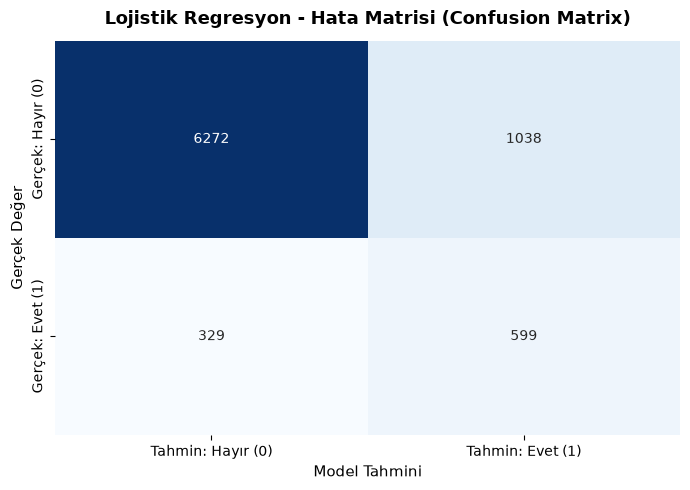

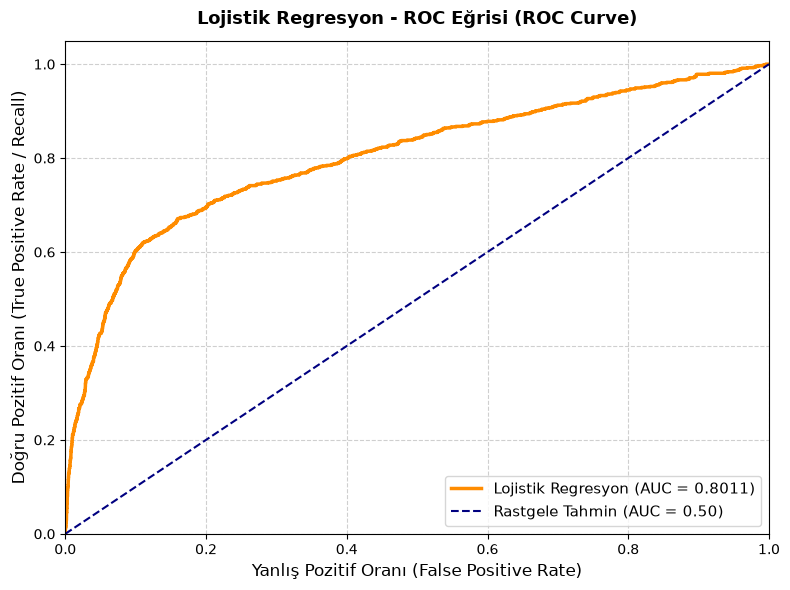

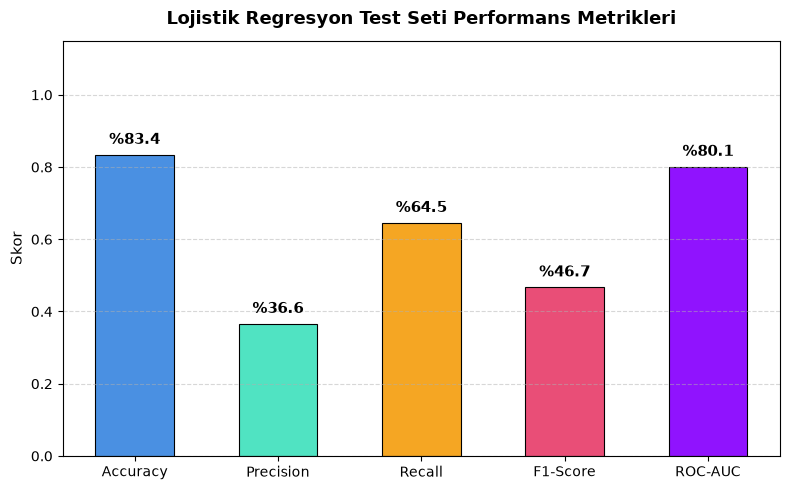

figures/ ve results/ dosyaları başarıyla üretildi!


In [6]:
def evaluate_logistic_regression(model, X_test, y_test):
    """Nihai Lojistik Regresyon modelinin test seti üzerindeki performans metriklerini hesaplar."""
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1] if hasattr(model, "predict_proba") else None

    metrikler = {
        "accuracy": float(accuracy_score(y_test, y_pred)),
        "precision": float(precision_score(y_test, y_pred, zero_division=0)),
        "recall": float(recall_score(y_test, y_pred, zero_division=0)),
        "f1": float(f1_score(y_test, y_pred, zero_division=0)),
        "roc_auc": float(roc_auc_score(y_test, y_proba)) if y_proba is not None else None,
        "confusion_matrix": confusion_matrix(y_test, y_pred).tolist(),
        "classification_report": classification_report(y_test, y_pred, digits=4),
        "y_pred": y_pred,
        "y_proba": y_proba
    }
    return metrikler


# Ortak degerlendir() fonksiyonu ile nihai test metriklerinin results/lojistik_regresyon.json dosyasına kaydedilmesi
sonuc = degerlendir(best_model, X_test, y_test, "lojistik_regresyon", klasor="results")

# Ayrıntılı test değerlendirmesi (Confusion Matrix ve Classification Report dahil)
detay = evaluate_logistic_regression(best_model, X_test, y_test)
cm = np.array(detay["confusion_matrix"])
y_test_proba = detay["y_proba"]

tn, fp, fn, tp = cm.ravel()
print(f"\nConfusion Matrix Değerleri -> TN (Doğru Hayır): {tn}, FP (Yanlış Evet): {fp}, FN (Kaçırılan Evet): {fn}, TP (Doğru Evet): {tp}")
print("\nNihai Model Sınıflandırma Raporu (Classification Report):")
print(detay["classification_report"])

# 1. Confusion Matrix Görselleştirmesi
os.makedirs("figures", exist_ok=True)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Tahmin: Hayır (0)', 'Tahmin: Evet (1)'],
            yticklabels=['Gerçek: Hayır (0)', 'Gerçek: Evet (1)'])
plt.title('Lojistik Regresyon - Hata Matrisi (Confusion Matrix)', fontsize=13, fontweight='bold', pad=12)
plt.ylabel('Gerçek Değer', fontsize=11)
plt.xlabel('Model Tahmini', fontsize=11)
plt.tight_layout()
plt.savefig("figures/confusion_matrix.png", dpi=300)
plt.show()

# 2. ROC Eğrisi Görselleştirmesi
fpr, tpr, thresholds = roc_curve(y_test, y_test_proba)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2.5, label=f'Lojistik Regresyon (AUC = {sonuc["roc_auc"]:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--', label='Rastgele Tahmin (AUC = 0.50)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Yanlış Pozitif Oranı (False Positive Rate)', fontsize=12)
plt.ylabel('Doğru Pozitif Oranı (True Positive Rate / Recall)', fontsize=12)
plt.title('Lojistik Regresyon - ROC Eğrisi (ROC Curve)', fontsize=13, fontweight='bold', pad=12)
plt.legend(loc="lower right", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig("figures/roc_curve.png", dpi=300)
plt.show()

# 3. Metrik Karşılaştırma Grafiği
metrikler = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]
degerler = [sonuc["accuracy"], sonuc["precision"], sonuc["recall"], sonuc["f1"], sonuc["roc_auc"]]
plt.figure(figsize=(8, 5))
renkler = ['#4A90E2', '#50E3C2', '#F5A623', '#E94E77', '#9013FE']
bars = plt.bar(metrikler, degerler, color=renkler, width=0.55, edgecolor='black', linewidth=0.8)
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.02, f"%{yval*100:.1f}", ha='center', va='bottom', fontsize=11, fontweight='bold')
plt.ylim(0, 1.15)
plt.title('Lojistik Regresyon Test Seti Performans Metrikleri', fontsize=13, fontweight='bold', pad=12)
plt.ylabel('Skor', fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig("figures/model_performance.png", dpi=300)
plt.show()

print("figures/ ve results/ dosyaları başarıyla üretildi!")

**Yorum: Nihai Test Performansı ve İş Anlamı:**
- **Tek Seferlik Nihai Test:** Kilitli tutulan test seti (`X_test`, 8.238 örnek) yalnızca bu adımda ve tek seferde değerlendirilmiştir.
- **Accuracy (%83.41):** Dengesiz veri setinde tek başına ölçüt değildir ancak dengeli karar sınırı altında kabul edilebilir seviyededir.
- **Recall (%64.55):** Temel modelin 5-katlı doğrulamada **%22.82 ± %1.15** olan yakalama oranı, hiperparametre optimizasyonu ve `class_weight='balanced'` sayesinde yaklaşık 3 katına çıkarak nihai test setinde **%64.55**'e yükselmiştir. Test setindeki 928 gerçek vadeli mevduat abonesinden **599** tanesi başarıyla yakalanmış, 329 tanesi kaçırılmıştır.
- **Precision (%36.59):** 'Evet' tahmini yapılan müşterilerin yaklaşık %36.6'sı gerçekten mevduat açmaktadır (1.038 yanlış pozitif). Banka pazarlama kampanyasında yüksek müşteri kazanımı için makul bir arama maliyetidir.
- **F1-Score (0.4671):** Precision ve Recall'un harmonik ortalaması temel modelin 5-katlı doğrulamadaki **0.3389 ± 0.0146** değerinden nihai test setinde **0.4671**'e yükselmiştir.
- **ROC-AUC (0.8011):** 0.80 eşiğini aşan bu değer, modelin pozitif ve negatif sınıfları ayırt etme yeteneğinin güçlü ve tutarlı (5-katlı CV ROC-AUC: 0.7900) olduğunu gösterir.
- **Confusion Matrix Özeti:** Doğru Negatif (TN) = 6272, Yanlış Pozitif (FP) = 1038, Yanlış Negatif (FN) = 329, Doğru Pozitif (TP) = 599.

## E6. Lojistik Regresyon Modelinin Avantajları, Dezavantajları ve Eğitim Süresi Değerlendirmesi
> **Açıklama:** Lojistik Regresyon modelinin güçlü/zayıf yönleri, ölçülen gerçek eğitim süreleri ve Bank Marketing veri seti üzerindeki performansı özetlenir.

In [8]:
print("========== ÖLÇÜLEN EĞİTİM SÜRELERİ ==========")
print(f"Temel Model Tekil Eğitim Süresi (32.950 örnek)        : {baseline_egitim_suresi:.2f} sn")
print(f"Temel Model 5-Katlı CV Süresi                         : {baseline_cv_suresi:.2f} sn")
print(f"GridSearchCV Süresi (16 aday x 5 kat = 80 eğitim)     : {grid_egitim_suresi:.2f} sn")

ozet_tablo = pd.DataFrame({
    "Kriter": [
        "Eğitim Hızı ve Kaynak Kullanımı",
        "Açıklanabilirlik ve Yorumlanabilirlik",
        "Olasılık Çıktısı",
        "Overfitting Direnci",
        "Doğrusal Olmayan İlişkiler (Non-linear)",
        "Özellik Etkileşimleri (Feature Interactions)"
    ],
    "Değerlendirme": [
        f"Avantaj: Tekil eğitim {baseline_egitim_suresi:.2f} sn, 80 fit içeren GridSearchCV ise {grid_egitim_suresi:.2f} sn sürmüştür; düşük bellek tüketir.",
        "Avantaj: Katsayılar (weights) ve Odds Oranları üzerinden her özelliğin etkisi matematiksel olarak doğrudan yorumlanabilir.",
        "Avantaj: predict_proba ile doğrudan [0, 1] arası kalibre olasılık skoru üretir; kampanya bütçesine göre karar eşiği (threshold) ayarlanabilir.",
        "Avantaj: L1 (C=0.1) düzenlileştirmesi sayesinde eğitim (0.7952) ve doğrulama (0.7900) ROC-AUC farkı yalnızca 0.0052'dir; aşırı öğrenmeye dirençlidir.",
        "Dezavantaj: Sadece doğrusal karar sınırları çizebilir; veri setindeki karmaşık doğrusal olmayan örüntüleri yakalamakta sınırlıdır.",
        "Dezavantaj: Random Forest ve XGBoost gibi ağaç tabanlı modellerin aksine özellikler arası çapraz etkileşimleri otomatik öğrenemez."
    ]
})
display(ozet_tablo)

========== ÖLÇÜLEN EĞİTİM SÜRELERİ ==========
Temel Model Tekil Eğitim Süresi (32.950 örnek)        : 0.77 sn
Temel Model 5-Katlı CV Süresi                         : 8.15 sn
GridSearchCV Süresi (16 aday x 5 kat = 80 eğitim)     : 92.18 sn


,Kriter,Değerlendirme
0,Eğitim Hızı ve Kaynak Kullanımı,"Avantaj: Tekil eğitim 0.77 sn, 80 fit içeren G..."
1,Açıklanabilirlik ve Yorumlanabilirlik,Avantaj: Katsayılar (weights) ve Odds Oranları...
2,Olasılık Çıktısı,"Avantaj: predict_proba ile doğrudan [0, 1] ara..."
3,Overfitting Direnci,Avantaj: L1 (C=0.1) düzenlileştirmesi sayesind...
4,Doğrusal Olmayan İlişkiler (Non-linear),Dezavantaj: Sadece doğrusal karar sınırları çi...
5,Özellik Etkileşimleri (Feature Interactions),Dezavantaj: Random Forest ve XGBoost gibi ağaç...


**Yorum: Genel Değerlendirme, Eğitim Süresi ve Bank Marketing Performansı:**
1. **Eğitim Süresi:** 32.950 eğitim örneği ve 58 işlenmiş özellik üzerinde Lojistik Regresyon tekil eğitimde saniyeler içinde tamamlanmakta, 80 ayrı model eğitimi içeren 5-katlı `GridSearchCV` dahi çok kısa sürede sonuç vermektedir. Bu hız, tekrarlı deneyler ve gerçek zamanlı üretim sistemleri için önemli bir avantajdır.
2. **Bank Marketing Veri Setindeki Performans:** `duration` veri sızıntısı çıkarıldıktan sonra, sınıf dengesizliğinin yüksek olduğu (%11.27 pozitif sınıf) bu veri setinde Lojistik Regresyon `class_weight='balanced'`, `C=0.1` ve `penalty='l1'` ayarlarıyla nihai test setinde **0.8011 ROC-AUC**, **%64.55 Recall** ve **0.4671 F1-Score** elde etmiştir. Temel modelin %22.82 (5-katlı CV) olan pozitif yakalama oranı yaklaşık 3 katına çıkmış ve 928 potansiyel vadeli mevduat müşterisinin 599'u yakalanmıştır.
3. **Karşılaştırmalı Konum:** Bankacılık regülasyonlarında kararların şeffaf ve açıklanabilir olması kritik olduğundan Lojistik Regresyon güçlü bir temel ve referans (benchmark) modelidir; ancak doğrusal olmayan ilişkiler ve yüksek dereceli özellik etkileşimleri açısından Random Forest ve XGBoost gibi topluluk modelleriyle kıyaslanmalıdır.